**ANOMALY FEATURE**

In [66]:
import digitalhub as dh
import os, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.covariance import ledoit_wolf_shrinkage


PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [67]:
job_name = "flood_pct_csv"

parameters = {
    "anomalies_artifact": "Floods_Anomalies_v3_crop_norm",   
    "output_name": "flood_pct_Floods_Anomalies_v3",
    "griglia": 0,           
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

In [3]:
ocsvm_func = project.new_function(
    name=f'diagnostica_vettori',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="utils:flood_pct_csv",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

In [4]:
resources = {"cpu": "4", "mem": "25Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="cpu-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-18 10:13:10,580 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:15,587 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:20,599 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:25,611 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:30,623 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:35,739 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10:13:40,751 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 246053dae1ef4ed89610df71e6b40fad to finish...
2026-11-18 10

Run anomaly detection ocsvm: 246053dae1ef4ed89610df71e6b40fad


In [75]:
VERSIONI = ["net_v5_msPre_pool8_vec", "net_v10_pool8_vec_v1", "net_v10_ms_v1_pool8_vec_v1"]
PUNTO = "encoder"
CANALI = {"encoder": 16, "encoder_fine": 16, "pre_proj": 128, "pre_proj_fine": 128, "pre_proj_ms": 128}

CARTELLA = "./vec"          

In [76]:
# download embedding da digitalhub

for ver in VERSIONI:
    dest = f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz"
    if os.path.exists(dest):
        print(f"{ver}: già presente"); continue
    os.makedirs(CARTELLA, exist_ok=True)
    p = project.get_artifact(f"anomaly_results_ocsvm_{ver}").download(f"{CARTELLA}/_tmp_{ver}.zip", overwrite=True)
    with zipfile.ZipFile(p) as z:
        membri = [f"{PUNTO}/embeddings.npz", "summary.json"]
        for m in membri:
            if m in z.namelist():
                z.extract(m, f"{CARTELLA}/{ver}")
        ok = f"{PUNTO}/embeddings.npz" in z.namelist()
    os.remove(p)
    print(f"{ver}: {'OK' if ok else 'PUNTO NON PRESENTE'}")

net_v5_msPre_pool8_vec: già presente
net_v10_pool8_vec_v1: già presente
net_v10_ms_v1_pool8_vec_v1: OK


In [77]:
# stampa configurazioni trovate per punto

dati = {}
for ver in VERSIONI:
    path = f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz"
    if not os.path.exists(path):
        print(f"{ver}: manca {PUNTO}, salto"); continue
    E = np.load(path)
    cat = lambda gr: np.concatenate([E[f"{gr}_q"], E[f"{gr}_k"]], axis=1).astype(np.float32)
    Dq, Dk = E["fit_q"].shape[1], E["fit_k"].shape[1]
    C = CANALI[PUNTO]
    g = int(round(np.sqrt(Dq / C)))
    assert C * g * g == Dq, f"{ver}: {Dq} dimensioni non sono {C} canali x griglia quadrata"
    dati[ver] = {"Xf": cat("fit"), "Xn": cat("normal"), "Xa": cat("anom"),
                 "Dq": Dq, "C": C, "g": g,
                 "anom_flood": E["anom_flood"] if "anom_flood" in E.files else None}
    print(f"{ver}: ottico {Dq} + SAR {Dk} = {Dq + Dk} dim | griglia {g}x{g}, {C} canali | "
          f"fit {len(dati[ver]['Xf'])}, normali {len(dati[ver]['Xn'])}, anomale {len(dati[ver]['Xa'])}")

net_v5_msPre_pool8_vec: ottico 256 + SAR 256 = 512 dim | griglia 4x4, 16 canali | fit 19893, normali 2402, anomale 2402
net_v10_pool8_vec_v1: ottico 1024 + SAR 1024 = 2048 dim | griglia 8x8, 16 canali | fit 19893, normali 2402, anomale 2402
net_v10_ms_v1_pool8_vec_v1: ottico 1024 + SAR 1024 = 2048 dim | griglia 8x8, 16 canali | fit 19893, normali 2402, anomale 2402


In [78]:
FLOOD_CSV = "./flood_pct_Floods_Anomalies_v3.csv"

fp = pd.read_csv(FLOOD_CSV, dtype={"ID": str}).set_index("ID")["flood_pct"]
print(f"CSV: {len(fp)} serie")

for ver, d in dati.items():
    ids = [str(i) for i in np.load(f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz")["anom_ids"]]
    d["anom_flood"] = fp.reindex(ids).values            # percentuale per ogni anomala, nello stesso ordine di Xa
    trovate = np.isfinite(d["anom_flood"]).sum()
    print(f"{ver}: {trovate} anomale su {len(ids)} trovate nel CSV", end="")
    if trovate:
        f = d["anom_flood"]
        print(f" | mediana {np.nanmedian(f):.1f}% | max {np.nanmax(f):.1f}%")
    else:
        print(f"  <-- nessun ID in comune. Esempio embedding: {ids[:2]} | esempio CSV: {list(fp.index[:2])}")

CSV: 2402 serie
net_v5_msPre_pool8_vec: 2402 anomale su 2402 trovate nel CSV | mediana 16.9% | max 100.0%
net_v10_pool8_vec_v1: 2402 anomale su 2402 trovate nel CSV | mediana 16.9% | max 100.0%
net_v10_ms_v1_pool8_vec_v1: 2402 anomale su 2402 trovate nel CSV | mediana 16.9% | max 100.0%


In [95]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

TARGET_LOG = False          
ALPHAS = np.logspace(-1, 6, 15)
N_FOLD = 5

def probe(X, y):
    """Ridge con alpha scelto internamente (RidgeCV) e predizioni fuori campione (validazione incrociata)."""
    modello = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))
    return cross_val_predict(modello, X, y, cv=KFold(N_FOLD, shuffle=True, random_state=0))

reg = {}
for ver, d in dati.items():
    if d.get("anom_flood") is None:
        continue
    y_pct = np.asarray(d["anom_flood"], dtype=float)
    ok = np.isfinite(y_pct)
    y = np.log1p(y_pct[ok]) if TARGET_LOG else y_pct[ok]
    Xa, Dq = d["Xa"][ok], d["Dq"]
    reg[ver] = {}
    for nome, X in (("OPT", Xa[:, :Dq]), ("SAR", Xa[:, Dq:]), ("OPT+SAR", Xa)):
        pred = probe(X, y)
        pred_pct = np.expm1(pred) if TARGET_LOG else pred
        reg[ver][nome] = {"y": y_pct[ok], "pred": pred_pct,
                          "R2": r2_score(y, pred), "Spearman": spearmanr(y, pred)[0],
                          "MAE (%)": mean_absolute_error(y_pct[ok], pred_pct)}
    if "score_a" in d:                                                  # lo score kNN (sezione 2) segue l'area?
        s = d["score_a"][0.5] if isinstance(d["score_a"], dict) else d["score_a"]
        reg[ver]["score kNN"] = {"Spearman": spearmanr(y_pct[ok], np.asarray(s)[ok])[0]}
    print(f"{ver}: fatto ({ok.sum()} anomale)")

net_v5_msPre_pool8_vec: fatto (2402 anomale)
net_v10_pool8_vec_v1: fatto (2402 anomale)
net_v10_ms_v1_pool8_vec_v1: fatto (2402 anomale)


In [96]:
print("versioni in reg:", list(reg))
print("FLOOD_CSV:", FLOOD_CSV, "| esiste:", os.path.exists(FLOOD_CSV) if FLOOD_CSV else "-")
for ver, d in dati.items():
    f = d.get("anom_flood")
    print(ver, "-> anom_flood:", "MANCANTE" if f is None else f"{np.isfinite(np.asarray(f, float)).sum()} valori validi su {len(f)}")

versioni in reg: ['net_v5_msPre_pool8_vec', 'net_v10_pool8_vec_v1', 'net_v10_ms_v1_pool8_vec_v1']
FLOOD_CSV: ./flood_pct_Floods_Anomalies_v3.csv | esiste: True
net_v5_msPre_pool8_vec -> anom_flood: 2402 valori validi su 2402
net_v10_pool8_vec_v1 -> anom_flood: 2402 valori validi su 2402
net_v10_ms_v1_pool8_vec_v1 -> anom_flood: 2402 valori validi su 2402


In [97]:
riassR = {}
for ver, r in reg.items():
    for nome, m in r.items():
        riassR[(ver, nome)] = {k: v for k, v in m.items() if k in ("R2", "Spearman", "MAE (%)")}
tabR = pd.DataFrame(riassR)
      
tabR.round(3)

net_v5_msPre_pool8_vec                            \
                            OPT     SAR OPT+SAR score kNN   
R2                        0.699   0.624   0.752       NaN   
Spearman                  0.768   0.723   0.805     0.157   
MAE (%)                  11.229  12.029   9.888       NaN   

         net_v10_pool8_vec_v1                            \
                          OPT     SAR OPT+SAR score kNN   
R2                      0.699   0.616   0.751       NaN   
Spearman                0.767   0.712   0.802     0.028   
MAE (%)                11.241  12.211   9.942       NaN   

         net_v10_ms_v1_pool8_vec_v1                            
                                OPT     SAR OPT+SAR score kNN  
R2                            0.699   0.616   0.751       NaN  
Spearman                      0.767   0.712   0.802     0.028  
MAE (%)                      11.241  12.211   9.942       NaN

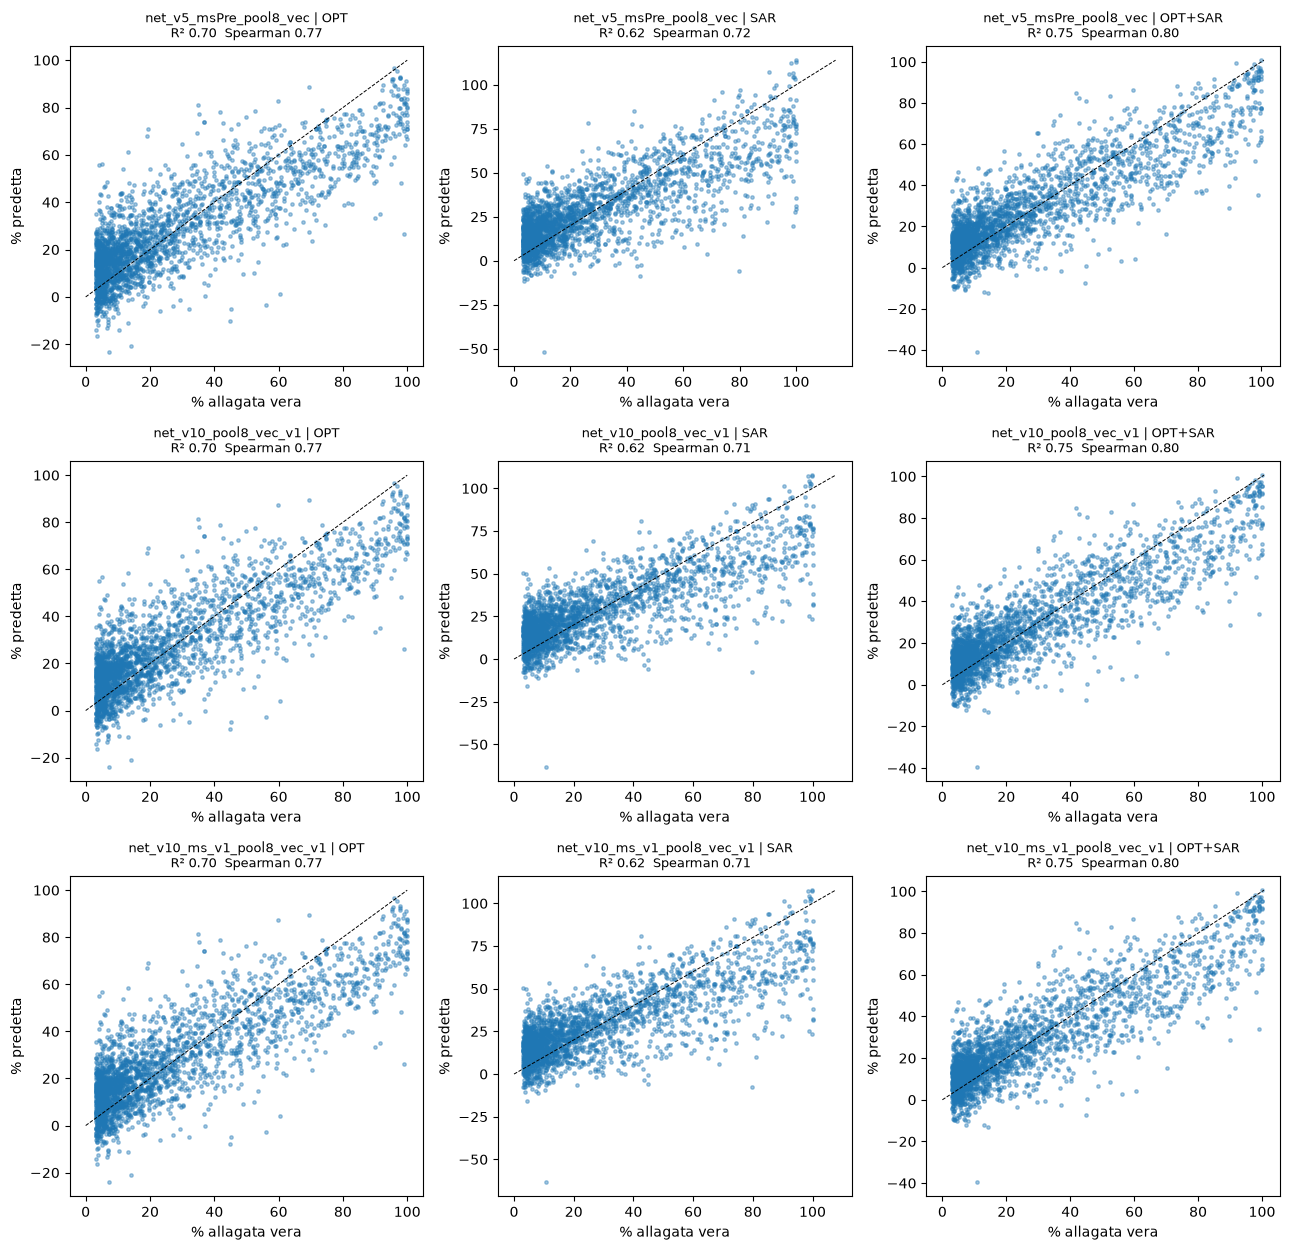

In [98]:
blocchi_R = ["OPT", "SAR", "OPT+SAR"]
fig, axs = plt.subplots(len(reg), 3, figsize=(13, 4.2 * len(reg)), squeeze=False)
for i, (ver, r) in enumerate(reg.items()):
    for j, nome in enumerate(blocchi_R):
        ax, m = axs[i, j], r[nome]
        ax.scatter(m["y"], m["pred"], s=6, alpha=.4)
        lim = [0, max(m["y"].max(), np.nanmax(m["pred"]))]
        ax.plot(lim, lim, "k--", lw=.7)                                
        ax.set_xlabel("% allagata vera"); ax.set_ylabel("% predetta")
        ax.set_title(f"{ver} | {nome}\nR² {m['R2']:.2f}  Spearman {m['Spearman']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

In [99]:
from sklearn.model_selection import StratifiedKFold

MIN_FLOOD_ANOM = 0.0        

def dati_con_normali(d):
    f = np.asarray(d["anom_flood"], dtype=float)
    ok = np.isfinite(f) & (f > MIN_FLOOD_ANOM)
    X = np.r_[d["Xn"], d["Xa"][ok]]
    y_pct = np.r_[np.zeros(len(d["Xn"])), f[ok]]                     
    etichetta = np.r_[np.zeros(len(d["Xn"])), np.ones(ok.sum())]    
    return X, y_pct, etichetta

regN = {}
for ver, d in dati.items():
    if d.get("anom_flood") is None:
        continue
    X, y_pct, lab = dati_con_normali(d)
    y = np.log1p(y_pct) if TARGET_LOG else y_pct
    cv = StratifiedKFold(N_FOLD, shuffle=True, random_state=0)
    Dq = d["Dq"]
    regN[ver] = {}
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None)), ("OPT+SAR", slice(None))):
        modello = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))
        pred = cross_val_predict(modello, X[:, sl], y, cv=cv.split(X, lab))
        pred_pct = np.expm1(pred) if TARGET_LOG else pred
        an = lab == 1
        regN[ver][nome] = {"y": y_pct, "pred": pred_pct, "lab": lab,          # salvati per i grafici
                           "R2 (tutte)": r2_score(y, pred),
                           "R2 (solo anomale)": r2_score(y[an], pred[an]),
                           "Spearman (tutte)": spearmanr(y, pred)[0],
                           "AUROC della % predetta": auroc(pred[~an], pred[an])}
    print(f"{ver}: {int((lab == 0).sum())} normali + {int(lab.sum())} anomale")

metriche_RN = ["R2 (tutte)", "R2 (solo anomale)", "Spearman (tutte)", "AUROC della % predetta"]
tabRN = pd.DataFrame({(v, n): {k: m[k] for k in metriche_RN} for v, r in regN.items() for n, m in r.items()})
tabRN.round(3)

net_v5_msPre_pool8_vec: 2402 normali + 2402 anomale
net_v10_pool8_vec_v1: 2402 normali + 2402 anomale
net_v10_ms_v1_pool8_vec_v1: 2402 normali + 2402 anomale


net_v5_msPre_pool8_vec                 \
                                          OPT    SAR OPT+SAR   
R2 (tutte)                              0.691  0.642   0.763   
R2 (solo anomale)                       0.672  0.566   0.730   
Spearman (tutte)                        0.726  0.643   0.748   
AUROC della % predetta                  0.862  0.797   0.868   

                       net_v10_pool8_vec_v1                 \
                                        OPT    SAR OPT+SAR   
R2 (tutte)                            0.688  0.623   0.757   
R2 (solo anomale)                     0.664  0.549   0.727   
Spearman (tutte)                      0.725  0.617   0.737   
AUROC della % predetta                0.861  0.780   0.860   

                       net_v10_ms_v1_pool8_vec_v1                 
                                              OPT    SAR OPT+SAR  
R2 (tutte)                                  0.688  0.623   0.757  
R2 (solo anomale)                           0.664  0.549   0.727  
Spearman (tutte)                            0.725  0.617   0.737  
AUROC della % predetta                      0.861  0.780   0.860

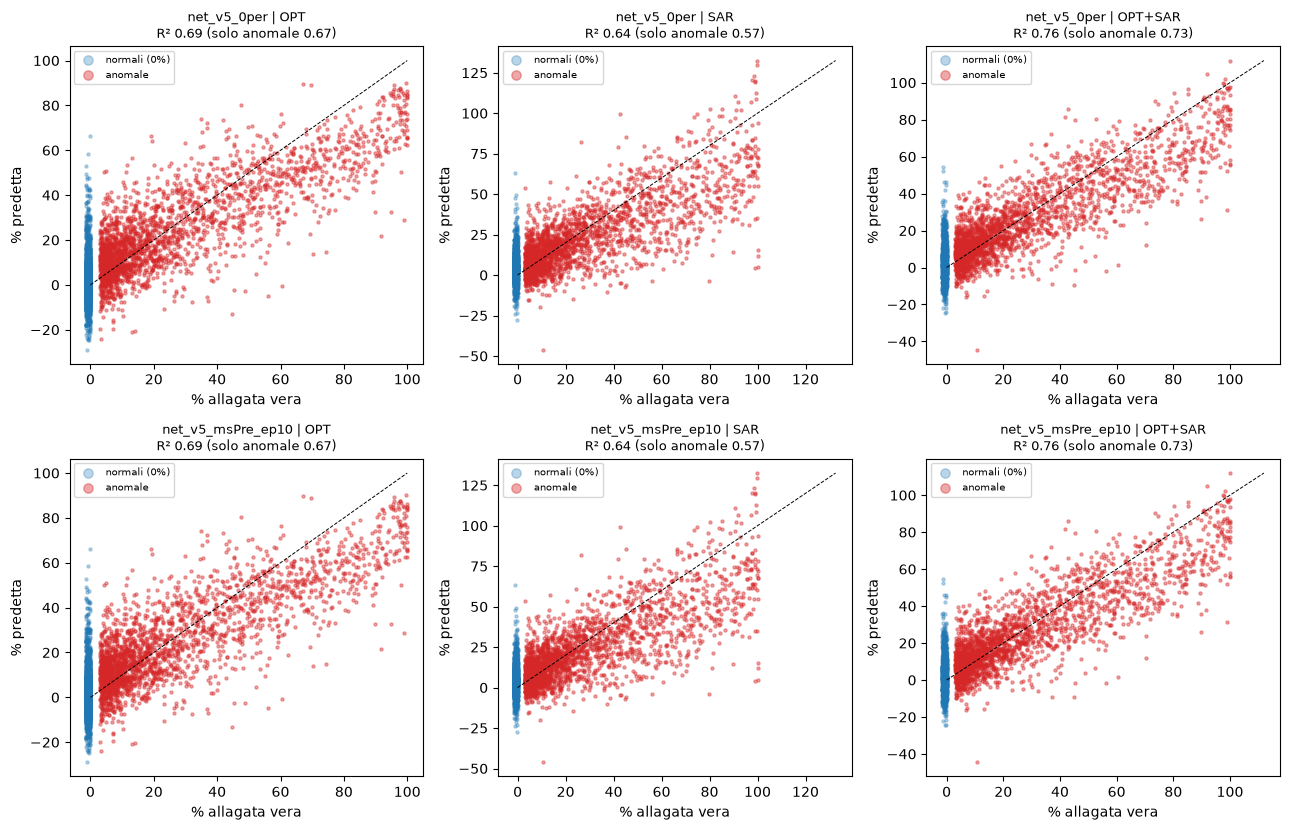

In [33]:
fig, axs = plt.subplots(len(regN), 3, figsize=(13, 4.2 * len(regN)), squeeze=False)
for i, (ver, r) in enumerate(regN.items()):
    for j, nome in enumerate(["OPT", "SAR", "OPT+SAR"]):
        ax, m = axs[i, j], r[nome]
        nor, an = m["lab"] == 0, m["lab"] == 1
        # le normali hanno tutte 0%: le sposto un po' in orizzontale per vederne la distribuzione verticale
        jit = np.random.default_rng(0).uniform(-1.5, 0, nor.sum())
        ax.scatter(m["y"][nor] + jit, m["pred"][nor], s=5, alpha=.3, label="normali (0%)")
        ax.scatter(m["y"][an], m["pred"][an], s=5, alpha=.4, color="tab:red", label="anomale")
        lim = [0, max(m["y"].max(), np.nanmax(m["pred"]))]
        ax.plot(lim, lim, "k--", lw=.7)
        ax.set_xlabel("% allagata vera"); ax.set_ylabel("% predetta")
        ax.set_title(f"{ver} | {nome}\nR² {m['R2 (tutte)']:.2f} (solo anomale {m['R2 (solo anomale)']:.2f})", fontsize=9)
        ax.legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

clf = {}
for ver, d in dati.items():
    if d.get("anom_flood") is None:
        continue
    X, y_pct, lab = dati_con_normali(d)
    cv = StratifiedKFold(N_FOLD, shuffle=True, random_state=0)
    Dq = d["Dq"]
    clf[ver] = {}
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None)), ("OPT+SAR", slice(None))):
        # regolarizzazione C scelta dentro ogni fold (validazione interna a 3 fold): niente fuga di informazione
        modello = GridSearchCV(
            make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=500, tol=1e-3, class_weight="balanced")),
            {"logisticregression__C": np.logspace(-4, -1, 4)},
            cv=3, scoring="roc_auc", n_jobs=-1)
        prob = cross_val_predict(modello, X[:, sl], lab, cv=cv.split(X, lab), method="predict_proba")[:, 1]
        clf[ver][nome] = auroc(prob[lab == 0], prob[lab == 1])
    print(f"{ver}: fatto")

tabC = pd.DataFrame(clf)
tabC.index.name = "AUROC lineare (supervisionato)"
tabC.round(3)

net_v5_0per: fatto
net_v5_msPre_ep10: fatto


,net_v5_0per,net_v5_msPre_ep10
AUROC lineare (supervisionato),,
OPT,0.891,0.891
SAR,0.875,0.875
OPT+SAR,0.927,0.927


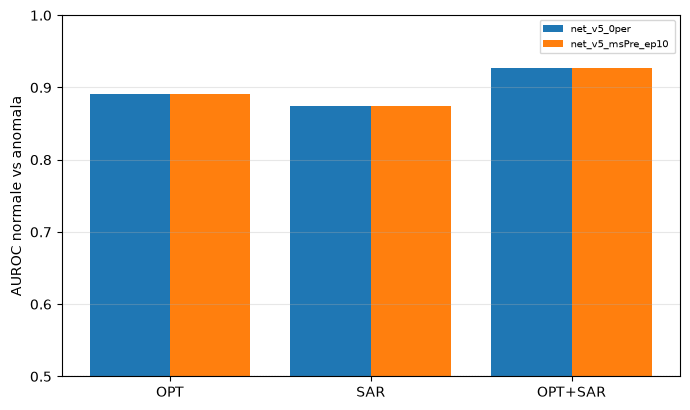

In [37]:
AUROC_KNN = {}              

fig, ax = plt.subplots(figsize=(7, 4.2))
blocchi_C = ["OPT", "SAR", "OPT+SAR"]
larg = .8 / max(1, len(clf))
for i, (ver, c) in enumerate(clf.items()):
    x = np.arange(len(blocchi_C)) + i * larg
    ax.bar(x, [c[b] for b in blocchi_C], width=larg, label=f"{ver} ")
    if ver in AUROC_KNN:
        ax.scatter(x, [AUROC_KNN[ver].get(b, np.nan) for b in blocchi_C], marker="_", s=400, lw=3,
                   color="k", zorder=3, label=f"{ver}")
ax.set_xticks(np.arange(len(blocchi_C)) + larg * (len(clf) - 1) / 2, blocchi_C)
ax.axhline(.5, color="gray", ls=":", lw=.8)
ax.set_ylim(.5, 1); ax.set_ylabel("AUROC normale vs anomala"); ax.legend(fontsize=7); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

In [79]:
# funzioni

def descrivi(j, Dq, C, g):
    mod = "OPT" if j < Dq else "SAR"
    c, r = divmod(j % Dq, g * g)
    return mod, c, r // g, r % g

def mostra_tabella(df, decimali=3, titolo=None, larghezza_col=1.6, evidenzia_max=False, file=None):
    """Mostra un DataFrame come immagine nel notebook. Se 'file' è dato, la salva anche su disco."""
    df = df.copy()
    if isinstance(df.index, pd.MultiIndex):                         # righe a più livelli -> testo
        df.index = [" | ".join(map(str, i)) for i in df.index]
    if isinstance(df.columns, pd.MultiIndex):                       # colonne a più livelli -> testo su più righe
        df.columns = ["\n".join(map(str, c)) for c in df.columns]
    df.columns = [str(c) for c in df.columns]
    testo = df.apply(lambda col: col.map(lambda v: "" if pd.isna(v) else
                     (f"{v:.{decimali}f}" if isinstance(v, (float, np.floating)) else str(v))))
    n_r, n_c = df.shape
    fig, ax = plt.subplots(figsize=(2.6 + larghezza_col * n_c, 0.6 + 0.32 * (n_r + 1)))
    ax.axis("off")
    t = ax.table(cellText=testo.values, rowLabels=[str(i) for i in df.index], colLabels=list(df.columns),
                 loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.4)
    righe_int = max(str(c).count("\n") + 1 for c in df.columns)
    for (r, c), cella in t.get_celld().items():
        if r == 0:
            cella.set_height(cella.get_height() * righe_int)
        if r == 0 or c == -1:
            cella.set_text_props(weight="bold"); cella.set_facecolor("#eeeeee")
    if evidenzia_max:
        num = df.apply(pd.to_numeric, errors="coerce")
        for r, (_, riga) in enumerate(num.iterrows(), start=1):
            if riga.notna().any():
                t[r, int(np.nanargmax(riga.values))].set_facecolor("#d6eaff")
    if titolo:
        ax.set_title(titolo, fontsize=11, pad=12)
    if file:
        fig.savefig(file, dpi=150, bbox_inches="tight")
    plt.show()



In [80]:
# calcolo auroc

def auroc_colonne(Xn, Xa):
    X = np.r_[Xn, Xa]
    r = rankdata(X, axis=0)                          
    n_n, n_a = len(Xn), len(Xa)
    a = (r[n_n:].sum(0) - n_a * (n_a + 1) / 2) / (n_n * n_a)
    return a, np.maximum(a, 1 - a)                   

for ver, d in dati.items():
    d["auroc_dir"], d["auroc"] = auroc_colonne(d["Xn"], d["Xa"])
    print(f"{ver}: ok")

net_v5_msPre_pool8_vec: ok
net_v10_pool8_vec_v1: ok
net_v10_ms_v1_pool8_vec_v1: ok


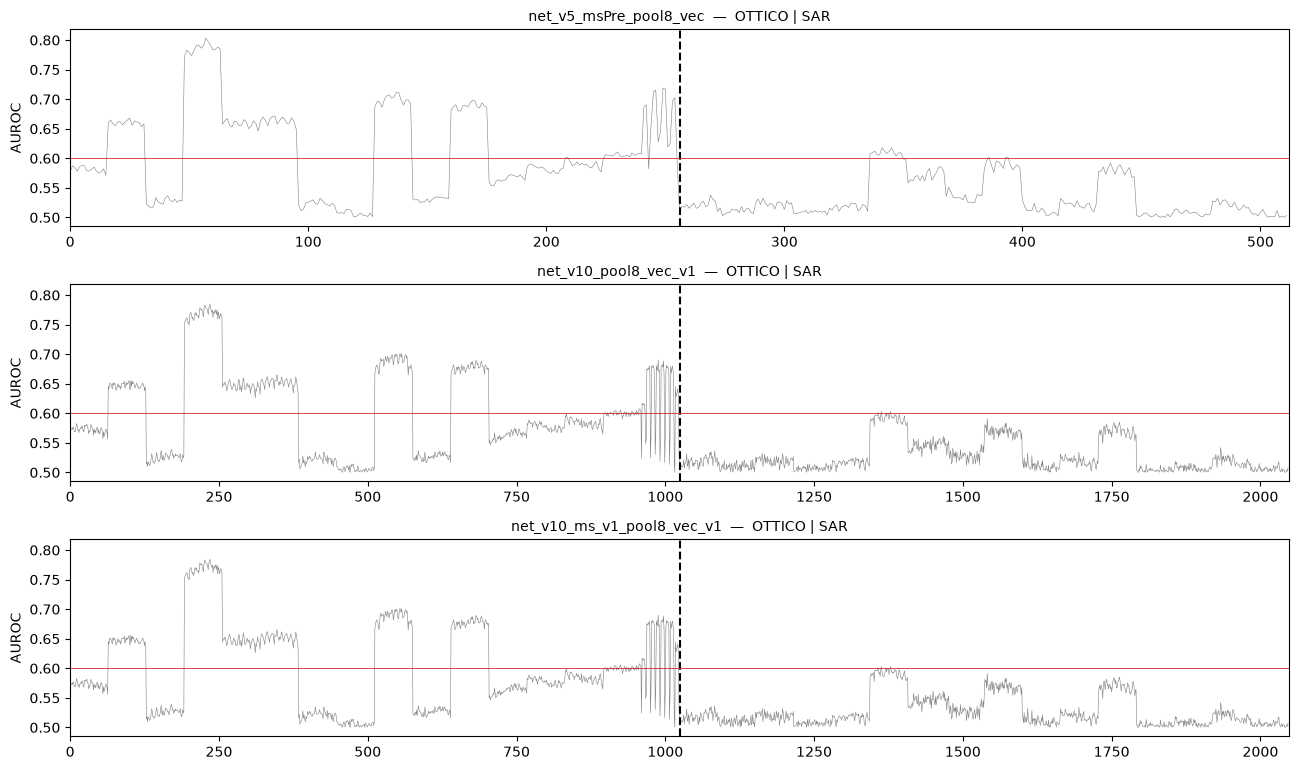

media  mediana    max  n > 0.6  quota > 0.6
net_v5_msPre_pool8_vec     OPT  0.614    0.598  0.803    128.0        0.500
                           SAR  0.534    0.520  0.618     17.0        0.066
net_v10_pool8_vec_v1       OPT  0.605    0.588  0.785    465.0        0.454
                           SAR  0.528    0.518  0.603      6.0        0.006
net_v10_ms_v1_pool8_vec_v1 OPT  0.605    0.588  0.785    465.0        0.454
                           SAR  0.528    0.518  0.603      6.0        0.006

In [81]:
# componenti piu significative -> 0.60 = info

fig, axs = plt.subplots(len(dati), 1, figsize=(13, 2.6 * len(dati)), squeeze=False, sharey=True)
for ax, (ver, d) in zip(axs[:, 0], dati.items()):
    ax.plot(d["auroc"], lw=.4, color="gray")
    ax.axvline(d["Dq"], color="k", ls="--")
    ax.axhline(.6, color="tab:red", lw=.6)
    ax.set_xlim(0, len(d["auroc"]))
    ax.set_title(f"{ver}  —  OTTICO | SAR", fontsize=10); ax.set_ylabel("AUROC")
plt.tight_layout(); plt.show()

riassunto = {}
for ver, d in dati.items():
    for mod, a in (("OPT", d["auroc"][:d["Dq"]]), ("SAR", d["auroc"][d["Dq"]:])):
        riassunto[(ver, mod)] = {"media": a.mean(), "mediana": np.median(a), "max": a.max(),
                                 "n > 0.6": int((a > .6).sum()), "quota > 0.6": (a > .6).mean()}
pd.DataFrame(riassunto).T.round(3)



In [82]:
# componenti piu significative -> tab

N_TOP = 10
tabelle = []
for ver, d in dati.items():
    for j in np.argsort(d["auroc"])[::-1][:N_TOP]:
        mod, c, r, col = descrivi(j, d["Dq"], d["C"], d["g"])
        tabelle.append({"versione": ver, "colonna": j, "modalità": mod, "canale": c, "cella": (r, col),
                        "AUROC": d["auroc"][j],
                        "direzione": "anom > norm" if d["auroc_dir"][j] > .5 else "anom < norm"})
top = pd.DataFrame(tabelle)
top.round(3)

,versione,colonna,modalità,canale,cella,AUROC,direzione
0,net_v5_msPre_pool8_vec,57,OPT,3,"(2, 1)",0.803,anom < norm
1,net_v5_msPre_pool8_vec,58,OPT,3,"(2, 2)",0.797,anom < norm
2,net_v5_msPre_pool8_vec,59,OPT,3,"(2, 3)",0.791,anom < norm
3,net_v5_msPre_pool8_vec,53,OPT,3,"(1, 1)",0.791,anom < norm
4,net_v5_msPre_pool8_vec,54,OPT,3,"(1, 2)",0.791,anom < norm
5,net_v5_msPre_pool8_vec,56,OPT,3,"(2, 0)",0.790,anom < norm
6,net_v5_msPre_pool8_vec,62,OPT,3,"(3, 2)",0.788,anom < norm
7,net_v5_msPre_pool8_vec,55,OPT,3,"(1, 3)",0.786,anom < norm
8,net_v5_msPre_pool8_vec,63,OPT,3,"(3, 3)",0.785,anom < norm
9,net_v5_msPre_pool8_vec,61,OPT,3,"(3, 1)",0.784,anom < norm


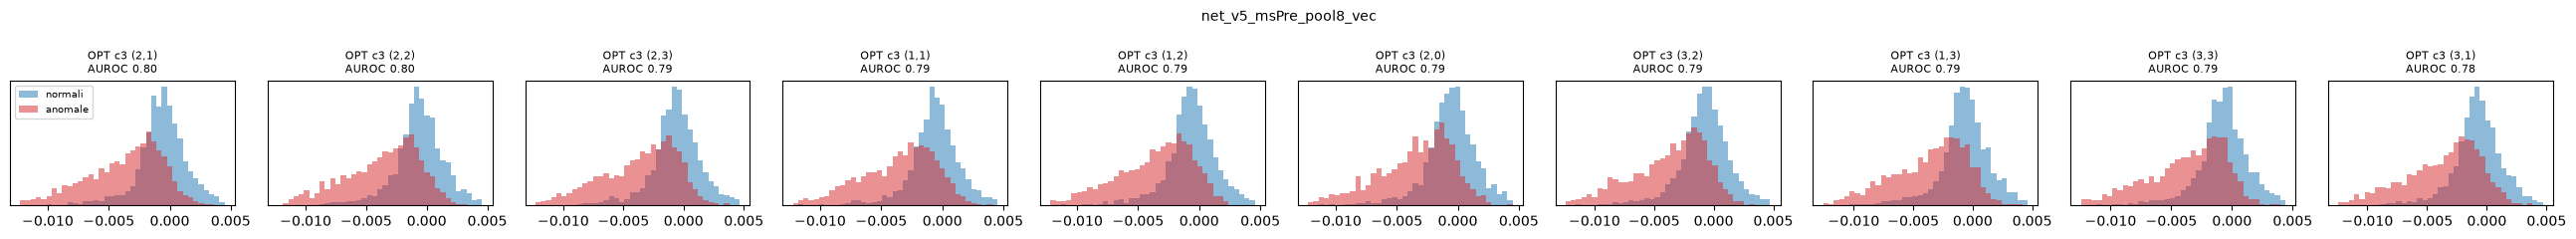

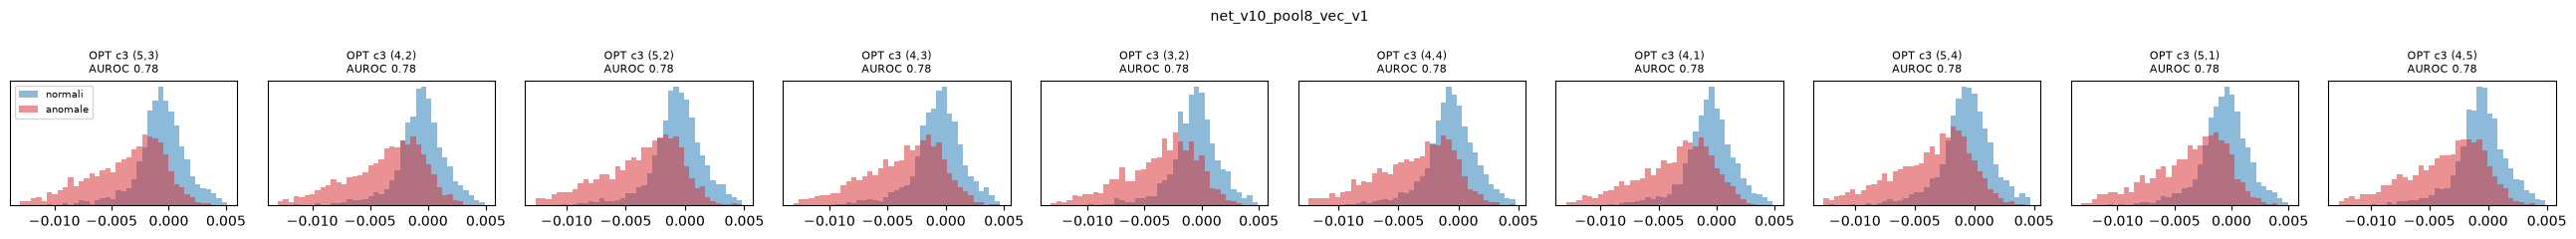

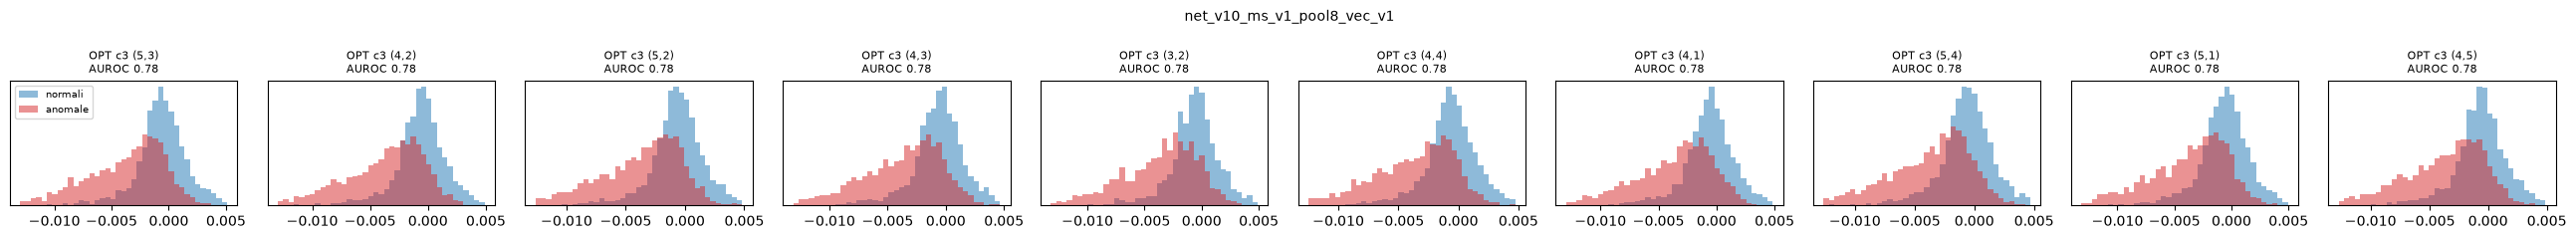

In [83]:
# componenti piu significative -> istogrammi

N_ISTO = 10
for ver, d in dati.items():
    fig, axs = plt.subplots(1, N_ISTO, figsize=(2.6 * N_ISTO, 2.4))
    for ax, j in zip(axs, np.argsort(d["auroc"])[::-1][:N_ISTO]):
        mod, c, r, col = descrivi(j, d["Dq"], d["C"], d["g"])
        bins = np.linspace(*np.percentile(np.r_[d["Xn"][:, j], d["Xa"][:, j]], [0.5, 99.5]), 40)
        ax.hist(d["Xn"][:, j], bins, alpha=.5, density=True, label="normali")
        ax.hist(d["Xa"][:, j], bins, alpha=.5, density=True, label="anomale", color="tab:red")
        ax.set_title(f"{mod} c{c} ({r},{col})\nAUROC {d['auroc'][j]:.2f}", fontsize=8)
        ax.set_yticks([])
    axs[0].legend(fontsize=7); fig.suptitle(ver, fontsize=10)
    plt.tight_layout(); plt.show()

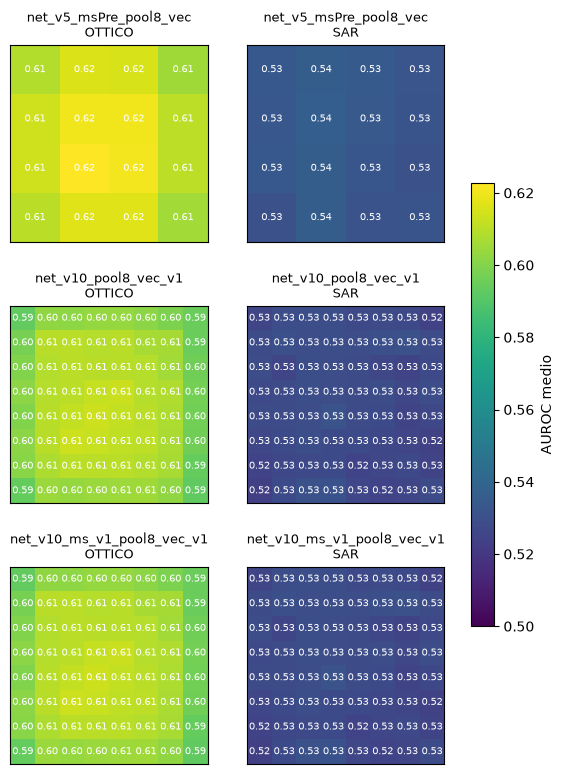

In [84]:
fig, axs = plt.subplots(len(dati), 2, figsize=(7, 3.2 * len(dati)), squeeze=False)
vmax = max(d["auroc"].reshape(2, d["C"], d["g"], d["g"]).mean(1).max() for d in dati.values())
for riga, (ver, d) in zip(axs, dati.items()):
    mappe = d["auroc"].reshape(2, d["C"], d["g"], d["g"]).mean(1)     # (modalità, g, g)
    for ax, m, nome in zip(riga, mappe, ("OTTICO", "SAR")):
        im = ax.imshow(m, vmin=.5, vmax=vmax, cmap="viridis")
        for (i, k), val in np.ndenumerate(m):
            ax.text(k, i, f"{val:.2f}", ha="center", va="center", fontsize=7, color="w")
        ax.set_title(f"{ver}\n{nome}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs, shrink=.6, label="AUROC medio")
plt.show()

**DIST EUC SAR vs OPT vs CONC**

In [85]:
# calcolo distanza euclidea sar vs ottico vs concatenazione

K = 1
PESI = np.round(np.linspace(0, 1, 11), 2)      
MAX_FIT = 5000                                 
BLOCCO = 500                                   

def auroc(sn, sa):
    return roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(sa))], np.r_[sn, sa])

def knn_euclidea(Zt, Zf, Dq, k=K, pesi=PESI, blocco=BLOCCO):
    
    Fq, Fk = Zf[:, :Dq], Zf[:, Dq:]
    nFq, nFk = (Fq ** 2).sum(1), (Fk ** 2).sum(1)
    score, opt, sar = {w: [] for w in pesi}, [], []
    for i in range(0, len(Zt), blocco):
        Tq, Tk = Zt[i:i + blocco, :Dq], Zt[i:i + blocco, Dq:]
        d_o = np.clip((Tq ** 2).sum(1)[:, None] + nFq[None] - 2 * Tq @ Fq.T, 0, None)
        d_s = np.clip((Tk ** 2).sum(1)[:, None] + nFk[None] - 2 * Tk @ Fk.T, 0, None)
        for w in pesi:
            d = w * d_o + (1 - w) * d_s
            vic = np.argpartition(d, k - 1, axis=1)[:, :k]
            score[w].append(np.take_along_axis(d, vic, 1).mean(1))
            if w == 0.5:
                opt.append(np.take_along_axis(d_o, vic, 1).mean(1))
                sar.append(np.take_along_axis(d_s, vic, 1).mean(1))
    return {w: np.concatenate(v) for w, v in score.items()}, (np.concatenate(opt), np.concatenate(sar))

for ver, d in dati.items():
    rng = np.random.default_rng(0)             
    Xf = d["Xf"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8      
    Zf, Zn, Za = (Xf - mu) / sd, (d["Xn"] - mu) / sd, (d["Xa"] - mu) / sd
    d["score_n"], d["parti_n"] = knn_euclidea(Zn, Zf, d["Dq"])
    d["score_a"], d["parti_a"] = knn_euclidea(Za, Zf, d["Dq"])
    print(f"{ver}: fatto")

net_v5_msPre_pool8_vec: fatto
net_v10_pool8_vec_v1: fatto
net_v10_ms_v1_pool8_vec_v1: fatto


In [86]:
riass1 = {}
for ver, d in dati.items():
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    curva = {w: auroc(d["score_n"][w], d["score_a"][w]) for w in PESI}
    d["curva_w"] = curva
    w_best = max(curva, key=curva.get)
    riass1[ver] = {
        "AUROC concatenato": curva[0.5],
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC solo SAR (w=0)": curva[0.0],
        "AUROC solo OPT (w=1)": curva[1.0],
        "quota OPT normali": (on / (on + sn)).mean(),
        "quota OPT anomale": (oa / (oa + sa)).mean(),
        "w migliore": w_best,
        "AUROC con w migliore": curva[w_best],
    }
pd.DataFrame(riass1).round(3)

,net_v5_msPre_pool8_vec,net_v10_pool8_vec_v1,net_v10_ms_v1_pool8_vec_v1
AUROC concatenato,0.849,0.862,0.862
AUROC parte OPT,0.822,0.818,0.818
AUROC parte SAR,0.834,0.855,0.855
AUROC solo SAR (w=0),0.833,0.864,0.864
AUROC solo OPT (w=1),0.825,0.821,0.821
quota OPT normali,0.453,0.412,0.412
quota OPT anomale,0.458,0.435,0.435
w migliore,0.400,0.200,0.200
AUROC con w migliore,0.849,0.869,0.869


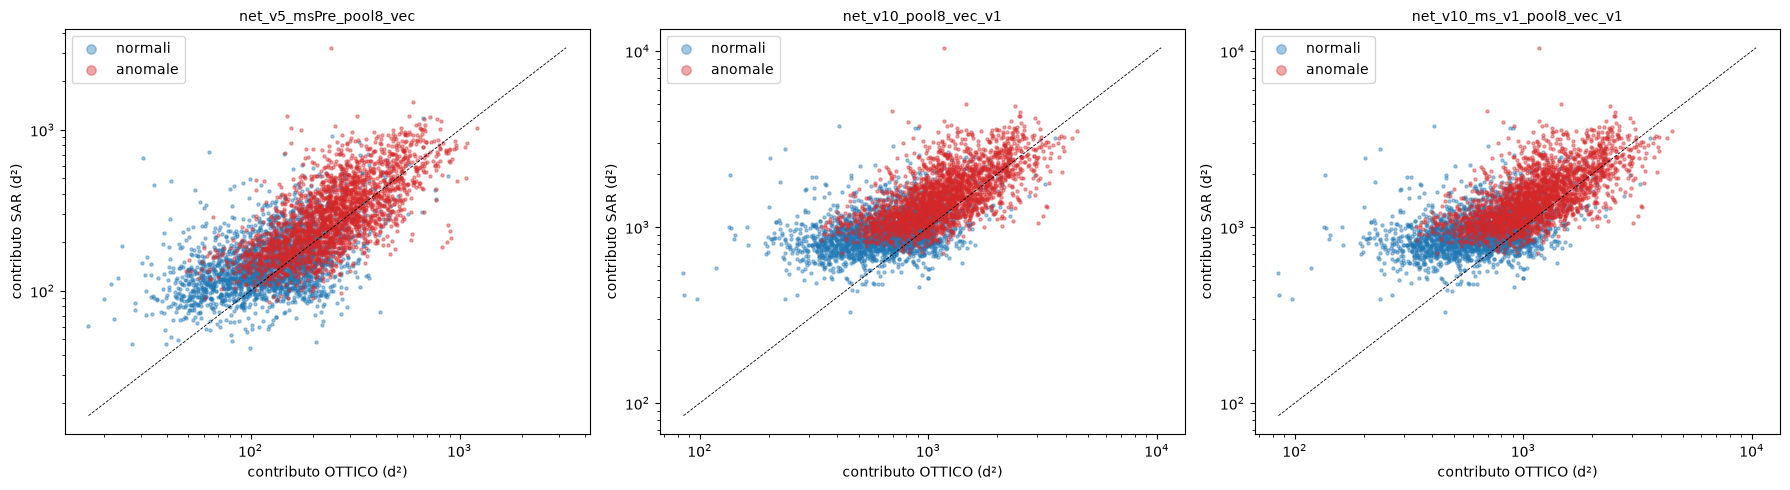

In [87]:
# è piu vicina la ka per ottico o sar

fig, axs = plt.subplots(1, len(dati), figsize=(6 * len(dati), 5), squeeze=False)
for ax, (ver, d) in zip(axs[0], dati.items()):
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)                          # sopra la diagonale: pesa più il SAR
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("contributo OTTICO (d²)"); ax.set_ylabel("contributo SAR (d²)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

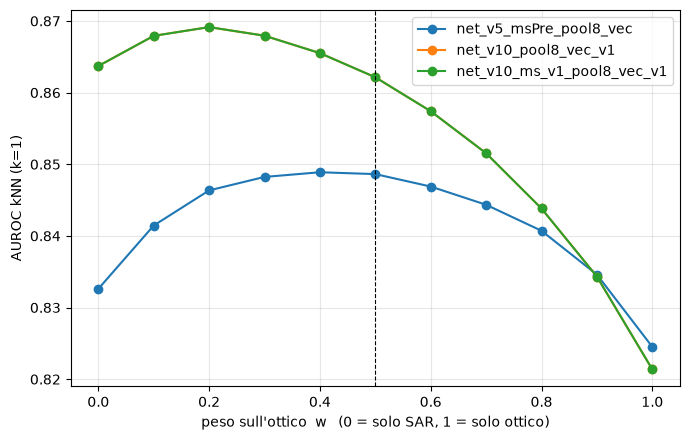

In [88]:
# auroc migliore a parità di percentuale di sar e ottico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    
    c = d["curva_w"]
    ax.plot(list(c), list(c.values()), marker="o", label=ver)
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN (k={K})"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**COSENO SAR vs OPT vs CONC**

In [89]:
# calcolo distanza coseno sar vs ottico vs concatenazione


K = 1
PESI = np.round(np.linspace(0, 1, 11), 2)      
MAX_FIT = 5000                                 
BLOCCO = 500                                   

def auroc(sn, sa):
    return roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(sa))], np.r_[sn, sa])

def knn_coseno(Xt, Xf, Dq, k=K, pesi=PESI, blocco=BLOCCO):
    
    nrm = lambda X: X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    Xt, Xf = nrm(Xt), nrm(Xf)                                   
    Fq, Fk = Xf[:, :Dq], Xf[:, Dq:]                             
    nFq, nFk = (Fq ** 2).sum(1), (Fk ** 2).sum(1)
    score, opt, sar = {w: [] for w in pesi}, [], []
    for i in range(0, len(Xt), blocco):
        Tq, Tk = Xt[i:i + blocco, :Dq], Xt[i:i + blocco, Dq:]
        
        d_o = np.clip((Tq ** 2).sum(1)[:, None] + nFq[None] - 2 * Tq @ Fq.T, 0, None)
        d_s = np.clip((Tk ** 2).sum(1)[:, None] + nFk[None] - 2 * Tk @ Fk.T, 0, None)
        for w in pesi:
            d = w * d_o + (1 - w) * d_s
            vic = np.argpartition(d, k - 1, axis=1)[:, :k]          
            score[w].append(np.take_along_axis(d, vic, 1).mean(1))
            if w == 0.5:                                           
                opt.append(np.take_along_axis(d_o, vic, 1).mean(1))
                sar.append(np.take_along_axis(d_s, vic, 1).mean(1))
    return {w: np.concatenate(v) for w, v in score.items()}, (np.concatenate(opt), np.concatenate(sar))

for ver, d in dati.items():
    rng = np.random.default_rng(0)             
                                               
    Xf = d["Xf"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    d["score_n"], d["parti_n"] = knn_coseno(d["Xn"], Xf, d["Dq"])
    d["score_a"], d["parti_a"] = knn_coseno(d["Xa"], Xf, d["Dq"])
    print(f"{ver}: fatto")

net_v5_msPre_pool8_vec: fatto
net_v10_pool8_vec_v1: fatto
net_v10_ms_v1_pool8_vec_v1: fatto


In [90]:
# risultati

riass2 = {}
for ver, d in dati.items():
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    curva = {w: auroc(d["score_n"][w], d["score_a"][w]) for w in PESI}
    d["curva_w"] = curva
    w_best = max(curva, key=curva.get)
    riass2[ver] = {
        "AUROC concatenato": curva[0.5],
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC solo SAR (w=0)": curva[0.0],
        "AUROC solo OPT (w=1)": curva[1.0],
        "quota OPT normali": (on / (on + sn)).mean(),
        "quota OPT anomale": (oa / (oa + sa)).mean(),
        "w migliore": w_best,
        "AUROC con w migliore": curva[w_best],
    }
pd.DataFrame(riass2).round(3)

,net_v5_msPre_pool8_vec,net_v10_pool8_vec_v1,net_v10_ms_v1_pool8_vec_v1
AUROC concatenato,0.678,0.635,0.635
AUROC parte OPT,0.658,0.618,0.618
AUROC parte SAR,0.724,0.701,0.701
AUROC solo SAR (w=0),0.723,0.682,0.682
AUROC solo OPT (w=1),0.659,0.619,0.619
quota OPT normali,0.876,0.879,0.879
quota OPT anomale,0.862,0.870,0.870
w migliore,0.100,0.100,0.100
AUROC con w migliore,0.734,0.698,0.698


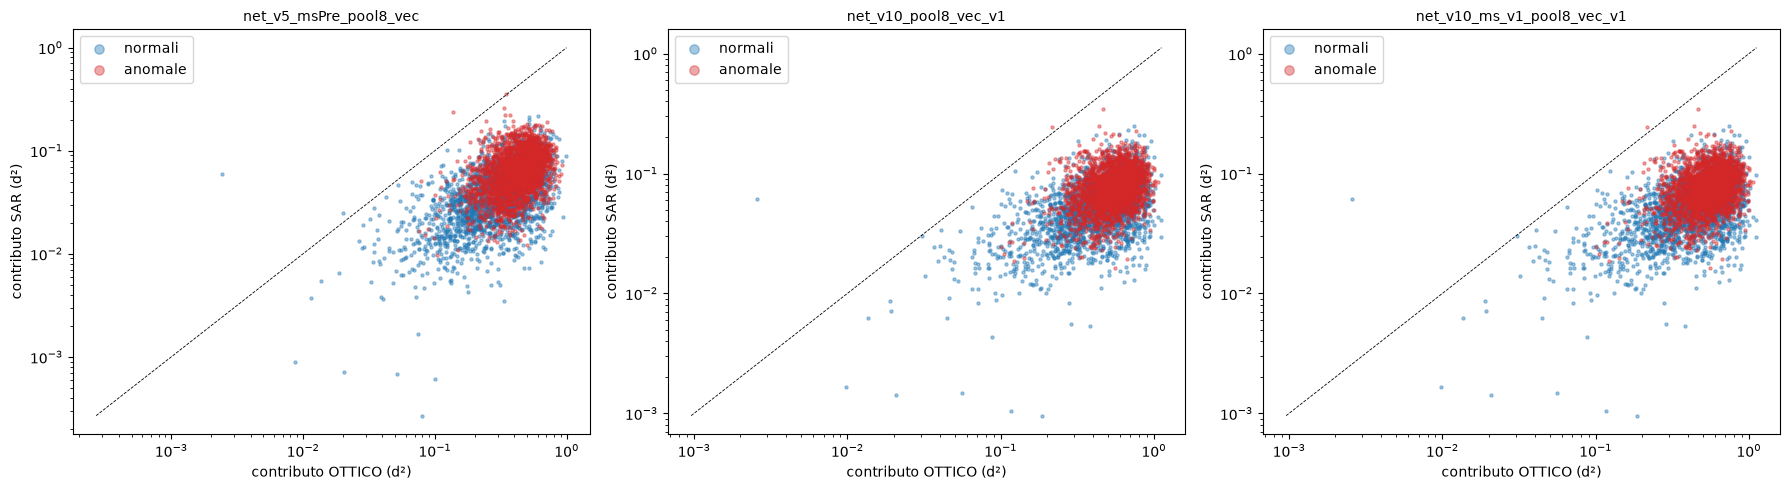

In [91]:
# è piu vicina la ka per ottico o sar

fig, axs = plt.subplots(1, len(dati), figsize=(6 * len(dati), 5), squeeze=False)
for ax, (ver, d) in zip(axs[0], dati.items()):
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)                          # sopra la diagonale: pesa più il SAR
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("contributo OTTICO (d²)"); ax.set_ylabel("contributo SAR (d²)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

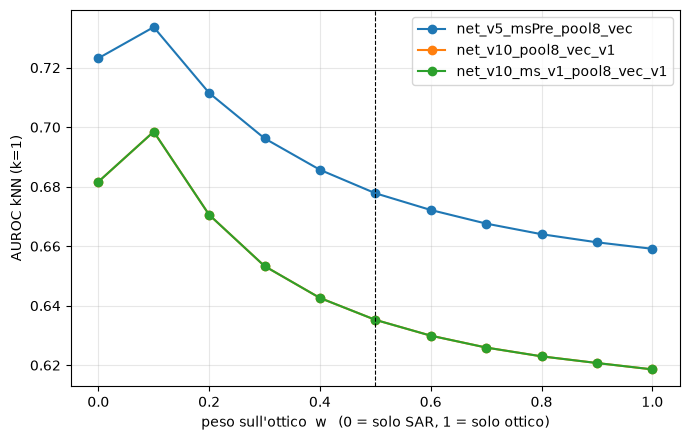

In [92]:
# auroc migliore a parità di percentuale di sar e ottico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    c = d["curva_w"]
    ax.plot(list(c), list(c.values()), marker="o", label=ver)
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN (k={K})"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**PCA LW SAR vs OPT vs CONC**

In [93]:
from sklearn.decomposition import PCA

N_COMP = 1024              

dati_lw = {}
for ver, d in dati.items():
    Dq = d["Dq"]
    if Dq <= N_COMP:                          
        dati_lw[ver] = d
        continue

    pca = {}
    for m, sl in (("o", slice(0, Dq)), ("s", slice(Dq, None))):
        pca[m] = PCA(N_COMP, random_state=0).fit(d["Xf"][:, sl])          

    nuovo = {"Dq": N_COMP + 1}                 
    for g in ("Xf", "Xn", "Xa"):
        parti = []
        for m, sl in (("o", slice(0, Dq)), ("s", slice(Dq, None))):
            X = d[g][:, sl]
            P = pca[m].transform(X)
            res = ((X - pca[m].inverse_transform(P)) ** 2).sum(1, keepdims=True)   
            parti.append(np.concatenate([P, np.log1p(res)], axis=1))             
        nuovo[g] = np.concatenate(parti, axis=1).astype(np.float32)

    dati_lw[ver] = nuovo
    var = [pca[m].explained_variance_ratio_.sum() for m in ("o", "s")]
    print(f"{ver}: {2 * Dq} -> {2 * (N_COMP + 1)} dim | varianza tenuta OPT {var[0]:.0%}, SAR {var[1]:.0%}")

In [94]:
for ver, d in dati.items():
    Dq = d["Dq"]
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None))):
        p = PCA(N_COMP, random_state=0).fit(d["Xf"][:, sl])
        res = lambda X: ((X - p.inverse_transform(p.transform(X))) ** 2).sum(1)   # quanto viene scartato
        print(f"{ver} {nome}: AUROC del residuo {auroc(res(d['Xn'][:, sl]), res(d['Xa'][:, sl])):.3f}")

ValueError: n_components=1024 must be between 0 and min(n_samples, n_features)=256 with svd_solver='covariance_eigh'

In [ ]:
# pca lw

K = 1
MAX_FIT = 5000
BLOCCO = 500                                   # riduci se finisce la RAM

def auroc(sn, sa):
    return roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(sa))], np.r_[sn, sa])

def prepara_lw(Xf):
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8
    Z = ((Xf - mu) / sd).astype(np.float64)
    alpha = ledoit_wolf_shrinkage(Z)
    lam, V = np.linalg.eigh(Z.T @ Z / len(Z))
    lam = (1 - alpha) * lam + alpha * lam.mean()
    return mu, sd, V / np.sqrt(lam), (V / lam) @ V.T

def knn_lw(Xt, Xf, prep, Dq=None, k=K, blocco=BLOCCO):
    mu, sd, W, P = prep
    Zt = (Xt - mu) / sd
    Zf = ((Xf - mu) / sd).astype(np.float64)
    Yf = Zf @ W; nYf = (Yf ** 2).sum(1)
    score, opt, sar, inc = [], [], [], []
    for i in range(0, len(Zt), blocco):
        Zb = Zt[i:i + blocco].astype(np.float64)
        Yb = Zb @ W
        d = np.clip((Yb ** 2).sum(1)[:, None] + nYf[None] - 2 * Yb @ Yf.T, 0, None)
        vic = np.argpartition(d, k - 1, axis=1)[:, :k]
        score.append(np.take_along_axis(d, vic, 1).mean(1))
        if Dq is not None:
            Delta = Zb[:, None, :] - Zf[vic]                          
            Do, Ds = Delta[..., :Dq], Delta[..., Dq:]
            opt.append(((Do @ P[:Dq, :Dq]) * Do).sum(-1).mean(1))      
            sar.append(((Ds @ P[Dq:, Dq:]) * Ds).sum(-1).mean(1))      
            inc.append(2 * ((Ds @ P[Dq:, :Dq]) * Do).sum(-1).mean(1))  
    score = np.concatenate(score)
    return (score, (np.concatenate(opt), np.concatenate(sar), np.concatenate(inc))) if Dq is not None else score

rng = np.random.default_rng(0)
for ver, d in dati_lw.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    if Xf.shape[1] > 4096:
        print(f"{ver}: {Xf.shape[1]} dimensioni, troppe per la lw, salto"); continue
    o, s = slice(0, Dq), slice(Dq, None)

    
    prep = prepara_lw(Xf)
    d["lw_score_n"], d["lw_parti_n"] = knn_lw(d["Xn"], Xf, prep, Dq)
    d["lw_score_a"], d["lw_parti_a"] = knn_lw(d["Xa"], Xf, prep, Dq)

    
    p_o, p_s = prepara_lw(Xf[:, o]), prepara_lw(Xf[:, s])
    so_n, so_a = knn_lw(d["Xn"][:, o], Xf[:, o], p_o), knn_lw(d["Xa"][:, o], Xf[:, o], p_o)
    ss_n, ss_a = knn_lw(d["Xn"][:, s], Xf[:, s], p_s), knn_lw(d["Xa"][:, s], Xf[:, s], p_s)
    d["lw_singole"] = {"solo SAR": (ss_n, ss_a), "solo OPT": (so_n, so_a)}

    def blocchi(X):                             
        mo, sdo, Wo, _ = p_o; ms, sds, Ws, _ = p_s
        return np.concatenate([((X[:, o] - mo) / sdo) @ Wo, ((X[:, s] - ms) / sds) @ Ws], axis=1).astype(np.float32)
    Bf = blocchi(Xf)
    ident = (np.zeros(Bf.shape[1]), np.ones(Bf.shape[1]), np.eye(Bf.shape[1]), None)   
    d["lw_singole"]["a blocchi"] = (knn_lw(blocchi(d["Xn"]), Bf, ident), knn_lw(blocchi(d["Xa"]), Bf, ident))
    print(f"{ver}: fatto")

KeyboardInterrupt: 

In [ ]:
# risultati

riass_lw = {}
for ver, d in dati.items():
    if "lw_parti_n" not in d:
        continue
    (on, sn, inc_n), (oa, sa, inc_a) = d["lw_parti_n"], d["lw_parti_a"]
    tot_n, tot_a = d["lw_score_n"], d["lw_score_a"]
    sing = {nome: auroc(*v) for nome, v in d["lw_singole"].items()}
    riass_lw[ver] = {
        "AUROC concatenato": auroc(tot_n, tot_a),
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC parte incrociata": auroc(inc_n, inc_a),
        "AUROC solo SAR": sing["solo SAR"],
        "AUROC solo OPT": sing["solo OPT"],
        "AUROC a blocchi": sing["a blocchi"],
        "quota OPT normali": (on / tot_n).mean(),
        "quota OPT anomale": (oa / tot_a).mean(),
        "quota SAR normali": (sn / tot_n).mean(),
        "quota SAR anomale": (sa / tot_a).mean(),
        "quota incrociata normali": (inc_n / tot_n).mean(),
        "quota incrociata anomale": (inc_a / tot_a).mean(),
        "guadagno vicini congiunti": sing["a blocchi"] - max(sing["solo SAR"], sing["solo OPT"]),
        "guadagno correlazione": auroc(tot_n, tot_a) - sing["a blocchi"],
    }
pd.DataFrame(riass_lw).round(3)

""


In [ ]:
# scatter

vers = [v for v in dati if "lw_parti_n" in dati[v]]
fig, axs = plt.subplots(1, len(vers), figsize=(6 * len(vers), 5), squeeze=False)
for ax, ver in zip(axs[0], vers):
    d = dati[ver]
    (on, sn, _), (oa, sa, _) = d["lw_parti_n"], d["lw_parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)
    ax.set_xlabel("parte OTTICA (lw)"); ax.set_ylabel("parte SAR (lw)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x500 with 0 Axes>

In [ ]:
# calcolo per grafico sotto

PESI = np.round(np.linspace(0, 1, 11), 2)

rng = np.random.default_rng(0)
for ver, d in dati.items():
    if "lw_parti_n" not in d:
        continue
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]   
    o, s = slice(0, Dq), slice(Dq, None)
    p_o, p_s = prepara_lw(Xf[:, o]), prepara_lw(Xf[:, s])     

    def sbianca(X, p):
        mu, sd, W, _ = p
        return (((X - mu) / sd) @ W).astype(np.float32)

    Yf = (sbianca(Xf[:, o], p_o), sbianca(Xf[:, s], p_s))
    Yn = (sbianca(d["Xn"][:, o], p_o), sbianca(d["Xn"][:, s], p_s))
    Ya = (sbianca(d["Xa"][:, o], p_o), sbianca(d["Xa"][:, s], p_s))
    curva = {}
    for w in PESI:
        
        pesa = lambda Y: np.concatenate([np.sqrt(w) * Y[0], np.sqrt(1 - w) * Y[1]], axis=1)
        F = pesa(Yf)
        I = (0, 1, np.eye(F.shape[1], dtype=np.float32), None)  
        curva[w] = auroc(knn_lw(pesa(Yn), F, I), knn_lw(pesa(Ya), F, I))
    d["lw_curva_w"] = curva
    w_best = max(curva, key=curva.get)
    print(f"{ver}: w migliore {w_best} (AUROC {curva[w_best]:.3f}) | lw completa {auroc(d['lw_score_n'], d['lw_score_a']):.3f}")

net_v5_msPre_pool8_vec: w migliore 0.0 (AUROC 0.922) | lw completa 0.885


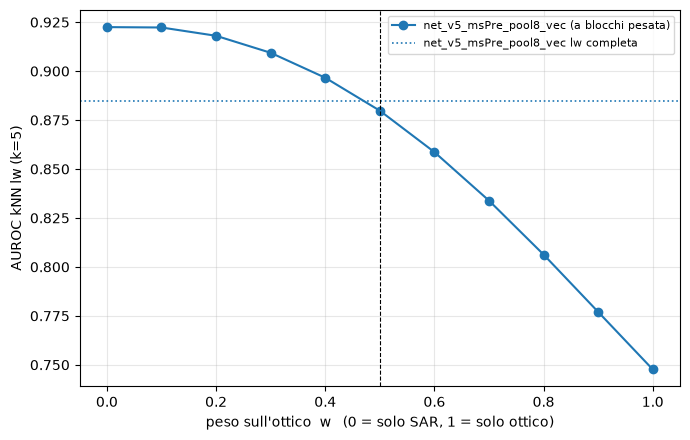

In [ ]:
# grafico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    if "lw_curva_w" not in d:
        continue
    c = d["lw_curva_w"]
    linea, = ax.plot(list(c), list(c.values()), marker="o", label=f"{ver} (a blocchi pesata)")
    ax.axhline(auroc(d["lw_score_n"], d["lw_score_a"]), color=linea.get_color(), ls=":", lw=1.2,
               label=f"{ver} lw completa")
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN lw (k={K})"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
# riassunto risultati

tutti = {"std": riass1, "coseno": riass2, "lw": riass_lw}

tab = pd.concat({dist: pd.DataFrame(r) for dist, r in tutti.items()}, axis=1)
tab.round(3)

In [ ]:
from sklearn.covariance import ledoit_wolf_shrinkage

MAX_FIT = 5000
TAGLI = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 4000]   # M = componenti grandi scartate

def curva_minori(Xf, Xn, Xa, tagli=TAGLI):
    """AUROC dello score 'distanza dalla media delle normali' usando solo le componenti dalla M+1 in poi + residuo."""
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8
    Zf = ((Xf - mu) / sd).astype(np.float64)
    c = Zf.mean(0)
    U, S, Vt = np.linalg.svd(Zf - c, full_matrices=False)       # tutte le componenti stimabili (≤ n_fit)
    lam = S ** 2 / (len(Zf) - 1)                                 # varianza di ogni componente
    alpha = ledoit_wolf_shrinkage(Zf)
    lam_s = (1 - alpha) * lam + alpha * lam.mean()               # shrinkage: evita di gonfiare le varianze minuscole
    out = {}
    for nome, X in (("n", Xn), ("a", Xa)):
        Z = ((X - mu) / sd).astype(np.float64) - c
        P = Z @ Vt.T                                             # coordinate su tutte le componenti
        res = (Z ** 2).sum(1) - (P ** 2).sum(1)                  # parte fuori da tutte le componenti stimabili
        contr = P ** 2 / lam_s                                   # contributo (sbiancato) di ogni componente
        coda = np.cumsum(contr[:, ::-1], axis=1)[:, ::-1]        # coda[:, M] = somma dalla componente M in poi
        out[nome] = (coda, res / (alpha * lam.mean()))           # residuo pesato come una direzione "solo shrinkage"
    curva = {}
    for M in tagli:
        if M >= len(lam):
            continue
        sn = out["n"][0][:, M] + out["n"][1]
        sa = out["a"][0][:, M] + out["a"][1]
        curva[M] = auroc(sn, sa)
    solo_res = auroc(out["n"][1], out["a"][1])
    return curva, solo_res, len(lam)

rng = np.random.default_rng(0)
minori = {}
for ver, d in dati.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    minori[ver] = {}
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None)), ("OPT+SAR", slice(None))):
        curva, solo_res, n_comp = curva_minori(Xf[:, sl], d["Xn"][:, sl], d["Xa"][:, sl])
        minori[ver][nome] = curva
        print(f"{ver} {nome}: {n_comp} componenti stimabili | solo residuo {solo_res:.3f} | "
              f"M migliore {max(curva, key=curva.get)} -> {max(curva.values()):.3f} (M=0: {curva[0]:.3f})")

fig, axs = plt.subplots(1, len(minori), figsize=(6 * len(minori), 4.5), squeeze=False)
for ax, (ver, cur) in zip(axs[0], minori.items()):
    for nome, c in cur.items():
        ax.plot(list(c), list(c.values()), marker="o", label=nome)
    ax.set_xscale("symlog", linthresh=1); ax.grid(alpha=.3)
    ax.set_xlabel("M = componenti più grandi scartate"); ax.set_ylabel("AUROC"); ax.set_title(ver, fontsize=10)
    ax.legend()
plt.tight_layout(); plt.show()

**PCA SPAZIO FEATURE**

In [ ]:

N_PC = 300                
MAX_FIT = 5000

rng = np.random.default_rng(0)
for ver, d in dati.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8                     
    n_pc = min(N_PC, len(Xf) - 1, Xf.shape[1])
    pca = PCA(n_pc, svd_solver="randomized", random_state=0).fit((Xf - mu) / sd)

    Pn = pca.transform((d["Xn"] - mu) / sd)                    
    Pa = pca.transform((d["Xa"] - mu) / sd)
    _, auroc_pc = auroc_colonne(Pn, Pa)                       

    load = pca.components_                                    
    quota_opt = (load[:, :Dq] ** 2).sum(1)                     

    d["pca"] = {"var": pca.explained_variance_ratio_, "var_tot": pca.explained_variance_ratio_.sum(),
                "quota_opt": quota_opt, "auroc": auroc_pc, "Pn": Pn, "Pa": Pa}
    print(f"{ver}: {n_pc} componenti, varianza spiegata {d['pca']['var_tot']:.0%}")

In [ ]:
fig, axs = plt.subplots(3, len(dati), figsize=(6 * len(dati), 8), squeeze=False, sharex="col")
for j, (ver, d) in enumerate(dati.items()):
    p = d["pca"]; x = np.arange(1, len(p["var"]) + 1)
    axs[0, j].plot(x, p["var"]); axs[0, j].set_yscale("log")
    axs[0, j].set_ylabel("varianza spiegata"); axs[0, j].set_title(ver, fontsize=10)
    axs[1, j].bar(x, p["quota_opt"], width=1, color="tab:green")
    axs[1, j].axhline(.5, color="k", ls="--", lw=.6); axs[1, j].set_ylim(0, 1)
    axs[1, j].set_ylabel("quota OTTICO")
    axs[2, j].bar(x, p["auroc"], width=1, color="tab:red")
    axs[2, j].axhline(.6, color="k", ls="--", lw=.6); axs[2, j].set_ylim(.5, max(.75, p["auroc"].max() + .02))
    axs[2, j].set_ylabel("AUROC componente"); axs[2, j].set_xlabel("componente (1 = più varianza)")
    for ax in axs[:, j]:
        ax.set_xscale("log")
plt.tight_layout(); plt.show()

In [ ]:
riass3 = {}
for ver, d in dati.items():
    p = d["pca"]; n = len(p["var"]); cum = np.cumsum(p["var"]) / p["var"].sum()
    top = np.argsort(p["auroc"])[::-1][:10]                    
    primi = slice(0, max(1, n // 10)); ultimi = slice(n - max(1, n // 10), n)
    riass3[ver] = {
        "componenti calcolate": n,
        "varianza spiegata (tot)": p["var_tot"],
        "componenti per 90% (delle calcolate)": int(np.searchsorted(cum, .9) + 1),
        "AUROC max componente": p["auroc"].max(),
        "posizione componente migliore": int(np.argmax(p["auroc"]) + 1),
        "posizione mediana top-10 AUROC": float(np.median(top + 1)),
        "AUROC medio primo 10% componenti": p["auroc"][primi].mean(),
        "AUROC medio ultimo 10% componenti": p["auroc"][ultimi].mean(),
        "quota OTTICO primo 10% componenti": p["quota_opt"][primi].mean(),
        "quota OTTICO top-10 AUROC": p["quota_opt"][top].mean(),
    }
pd.DataFrame(riass3).round(3)

In [ ]:
fig, axs = plt.subplots(2, len(dati), figsize=(5.5 * len(dati), 10), squeeze=False)
for j, (ver, d) in enumerate(dati.items()):
    p = d["pca"]
    best = np.argsort(p["auroc"])[::-1][:2]                    # le due componenti più discriminanti
    for i, (c1, c2, tit) in enumerate(((0, 1, "più varianza"), (best[0], best[1], "più discriminanti"))):
        ax = axs[i, j]
        ax.scatter(p["Pn"][:, c1], p["Pn"][:, c2], s=4, alpha=.4, label="normali")
        ax.scatter(p["Pa"][:, c1], p["Pa"][:, c2], s=4, alpha=.4, label="anomale", color="tab:red")
        ax.set_xlabel(f"PC{c1 + 1}  (OPT {p['quota_opt'][c1]:.0%}, AUROC {p['auroc'][c1]:.2f})", fontsize=8)
        ax.set_ylabel(f"PC{c2 + 1}  (OPT {p['quota_opt'][c2]:.0%}, AUROC {p['auroc'][c2]:.2f})", fontsize=8)
        ax.set_title(f"{ver}\n{tit}", fontsize=9); ax.legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

**CANCELLA CARTELLA**

In [100]:
import shutil, glob

TUTTO = True
ESEGUI = True              

def dimensione(path):
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs)

if TUTTO:
    bersagli = [CARTELLA] if os.path.exists(CARTELLA) else []
else:
    bersagli = [f"{CARTELLA}/{ver}/{PUNTO}" for ver in VERSIONI if os.path.exists(f"{CARTELLA}/{ver}/{PUNTO}")]
    bersagli += glob.glob(f"{CARTELLA}/_tmp_*.zip")

totale = 0
for b in bersagli:
    mb = dimensione(b) / 1e6; totale += mb
    print(f"{'cancello' if ESEGUI else 'da cancellare'}: {b}  ({mb:.0f} MB)")
    if ESEGUI:
        shutil.rmtree(b) if os.path.isdir(b) else os.remove(b)

if ESEGUI and not TUTTO:                      # rimuove le cartelle di versione rimaste vuote
    for ver in VERSIONI:
        d = f"{CARTELLA}/{ver}"
        if os.path.isdir(d) and all(f == "summary.json" for f in os.listdir(d)):
            shutil.rmtree(d)

print(f"{'liberati' if ESEGUI else 'liberabili'}: {totale:.0f} MB" if bersagli else "niente da cancellare")

cancello: ./vec  (2992 MB)
liberati: 2992 MB


In [101]:
# libera anche la RAM occupata dagli embedding caricati (facoltativo)
for nome in ("dati", "top", "riassunto"):
    globals().pop(nome, None)
import gc; gc.collect()

145290